In [2]:
import numpy as np
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# ==================== GALPY ====================
LOG10_MVIR_MSUN = 13.5
M_VIR_1E12 = 10 ** (LOG10_MVIR_MSUN - 12.0)
C_HOST = 6.5

RO = 1.0
VO = 110.0

KPC_PER_GYR_PER_KMS = 1.022712
RO_KPC = RO
VO_KMS = VO
T_UNIT_GYR = RO_KPC / (VO_KMS * KPC_PER_GYR_PER_KMS)

# ---- Initial conditions ----
R_VIR_KPC = 974.407
R0_KPC = 0.7 * R_VIR_KPC
z0_KPC = 0.0
phi0_RAD = 0.0

vR0_KMS = 0.0
vT0_KMS = 33.1515
vz0_KMS = 0.0

T_MAX_GYR = 10.0
N_STEPS = 2001

pot = NFWPotential(
    mvir=M_VIR_1E12,
    conc=C_HOST,
    ro=RO,
    vo=VO
)

R0_g = R0_KPC / RO_KPC
z0_g = z0_KPC / RO_KPC
vR0_g = vR0_KMS / VO_KMS
vT0_g = vT0_KMS / VO_KMS
vz0_g = vz0_KMS / VO_KMS
phi0 = phi0_RAD

orb = Orbit(
    vxvv=[R0_g, vR0_g, vT0_g, z0_g, vz0_g, phi0],
    ro=RO,
    vo=VO
)

# ==========================
# INTEGRATION
# ==========================

tmax_galpy = T_MAX_GYR / T_UNIT_GYR
t_galpy = np.linspace(0.0, tmax_galpy, N_STEPS)

orb.integrate(t_galpy, pot)

t_Gyr = t_galpy * T_UNIT_GYR


Processing subhalo_evp_3_1_1/AHFout...
Processing SIDM_AHFout...
Processing CDM_AHFout...


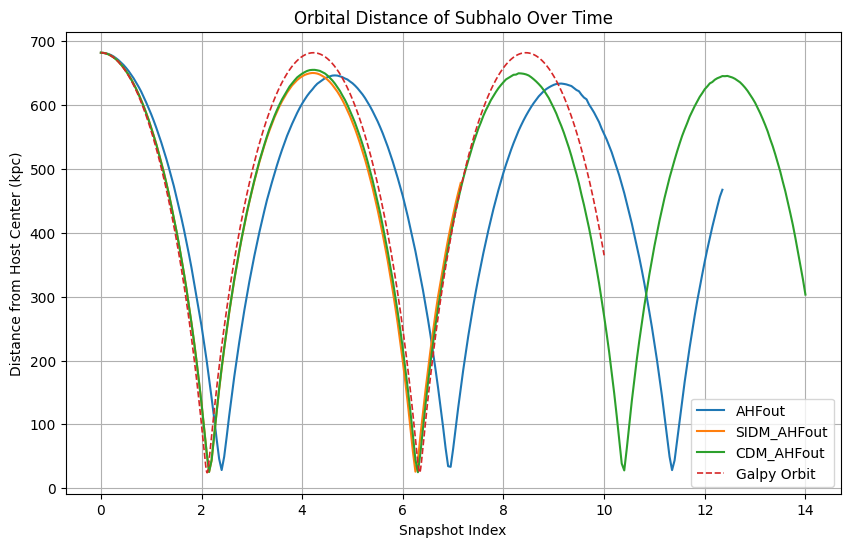

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIG & CONSTANTS ====================
BASE_PATH = "./Data/"
# List your folder names here
FOLDERS = ["subhalo_evp_3_1_1/AHFout", "SIDM_AHFout", "CDM_AHFout"] 
TOTAL_SNAPS = 280
HOST_CENTER = np.array([10000.0, 10000.0, 10000.0])

# ==================== HELPER FUNCTION ====================
def read_subhalo_data(folder_name):
    """Reads snapshot data from a specific folder."""
    coords = []
    ahf_dir = os.path.join(BASE_PATH, folder_name)
    
    for i in range(TOTAL_SNAPS + 1):
        path = os.path.join(ahf_dir, f"{i}-halos")
        if not os.path.exists(path): continue
        
        with open(path, 'r') as f:
            lines = f.readlines()
            for line in lines[1:]:
                cols = line.split()
                # Assuming index 1 is hostHalo; adjusting for first subhalo
                pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                coords.append(pos - HOST_CENTER)
                # print(pos)  # Debug: print the last read position
    return np.array(coords)

# ==================== PROCESSING MULTIPLE FOLDERS ====================
all_sims = {}

for folder in FOLDERS:
    print(f"Processing {folder}...")
    data = read_subhalo_data(folder)
    if len(data) > 0:
        all_sims[folder] = data

# orbital distance plot for both galpy and AHF data
R = orb.R(t_galpy) * RO_KPC

# snapshot with corresponding time in Gyr
DT_SNAP = 0.05

plt.figure(figsize=(10, 6))
for folder, data in all_sims.items():
    distances = np.linalg.norm(data, axis=1)
    final_snap = len(distances) - 1
    snap_times = np.arange(0, (final_snap + 1) * DT_SNAP, DT_SNAP)
    plt.plot(snap_times, distances, label=folder.split('/')[-1])
plt.plot(t_Gyr, R, lw=1.2, label="Galpy Orbit", ls='--')
plt.xlabel("Snapshot Index")
plt.ylabel("Distance from Host Center (kpc)")
plt.title("Orbital Distance of Subhalo Over Time")
plt.legend()
plt.grid()
plt.show()
